In [1]:
import sys, os, warnings
import numpy as np
import pandas as pd
import xarray as xr
from datetime import datetime

from utils.post_process import merge_bursts
from seasonal_burst.exhaustive_search import exhaustive_search_intra_period
import utils_notebook as utils

import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

import matplotlib.cm as cm
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
import matplotlib.colors as mcolors


import pymannkendall as mk

import plotly.offline as pyo
import plotly.graph_objs as go

from seasonal_burst.online_algorithm import WelfordBurstDetector

# Set notebook mode to work
pyo.init_notebook_mode()

online = False

In [2]:
start_year = 1974
end_year = 2023
n_year = end_year - start_year + 1
len_year = 92 * 24

ds = xr.open_dataset("wgbt_era5_Paris_1974-2023jja.nc")
ts_wbgt = ds.wbgt.values.ravel().astype(np.float64)
ts_date = pd.DatetimeIndex(ds.time.values)
ts_tas = xr.open_dataset("ta_era5_Paris_1974-2023jja.nc").t2m.values.ravel().astype(np.float64) - 273.15
ts_mort = np.load("mortality.npy").astype(np.float64)#[24*92:-4*92]

mask = (ts_date.year >= start_year) & (ts_date.year <= end_year)
ts_wbgt = ts_wbgt[mask]
ts_tas = ts_tas[mask]
ts_date = ts_date[mask]

tas_yearly = np.copy(ts_tas.reshape((n_year, len_year)))
wbgt_yearly = np.copy(ts_wbgt.reshape((n_year, len_year)))
mort_yearly = np.copy(ts_mort.reshape((n_year, len_year//24)))

In [3]:
ts_date_days = pd.date_range('01-Jan-1974', '31-Dec-2023', freq='D')
ts_date_days = ts_date_days[ts_date_days.month.isin([6, 7, 8])]

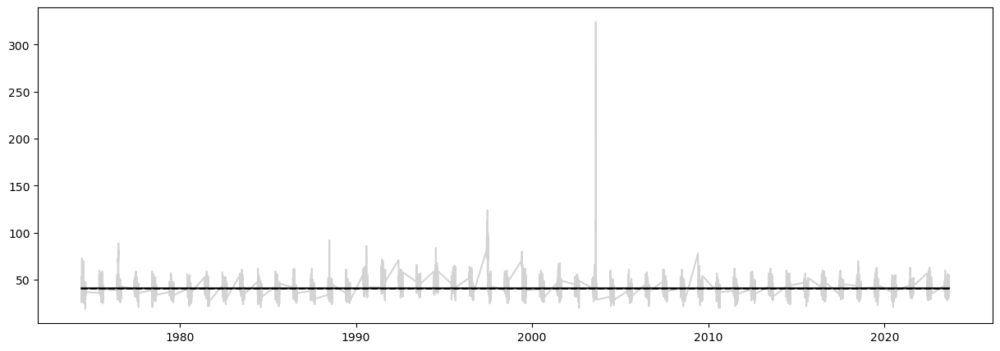

In [4]:
test_all = mk.seasonal_test(ts_mort, period=92)
trend_line_all = np.arange(len(ts_mort))/ (92) * test_all.slope + test_all.intercept

plt.figure(figsize=(15,5))
plt.plot(ts_date_days, ts_mort, color="lightgray")
plt.plot(ts_date_days, trend_line_all, color="black")
plt.hlines(test_all.intercept, ts_date_days[0], ts_date_days[-1], color="black", ls="dashed")
plt.show()

In [5]:
test_all

Seasonal_Mann_Kendall_Test(trend='increasing', h=np.True_, p=np.float64(0.03213936585807242), z=np.float64(2.142672987806885), Tau=np.float64(0.02175687666370896), s=np.float64(2452.0), var_s=np.float64(1308503.3333333337), slope=np.float64(0.0), intercept=np.float64(41.0))

In [6]:
threshold = 2.5
minimum_length = 1
maximum_length = 10*24

In [7]:
if not online:
    tas_bursts = exhaustive_search_intra_period(ts_tas, n_year, threshold, len_year, minimum_length, maximum_length)
    tas_bursts_merged = merge_bursts(tas_bursts)
    tas_bursts = [b for b in tas_bursts_merged if b[2] >0]
    
    wbgt_bursts = exhaustive_search_intra_period(ts_wbgt, n_year, threshold, len_year, minimum_length, maximum_length)
    wbgt_bursts_merged = merge_bursts(wbgt_bursts)
    wbgt_bursts = [b for b in wbgt_bursts_merged if b[2] >0]
    
    mort_bursts = exhaustive_search_intra_period(ts_mort, n_year, threshold, 92, 1, 10)
    mort_bursts_merged = merge_bursts(mort_bursts)
    mort_bursts = [b for b in mort_bursts_merged if b[2] >0]

else:
    tas_bursts = []
    wbgt_bursts = []
    mort_bursts = []
    
    start_years = 20
    for years in range(start_years, n_year):
        ts_tas_init = ts_tas[:years * len_year]
        ts_wbgt_init = ts_wbgt[:years * len_year]
        ts_mort_tas_init = ts_mort[:years * 92]

        bursts = exhaustive_search_intra_period(ts_tas_init, years, threshold, len_year, minimum_length, maximum_length)
        tas_bursts_merged = merge_bursts(bursts)
        tas_bursts_merged = [b for b in tas_bursts_merged if b[2] >0 and b[1]//len_year==years-1]
        
        bursts = exhaustive_search_intra_period(ts_wbgt_init, years, threshold, len_year, minimum_length, maximum_length)
        wbgt_bursts_merged = merge_bursts(bursts)
        wbgt_bursts_merged =  [b for b in wbgt_bursts_merged if b[2] >0 and b[1]//len_year==years-1]
        
        bursts = exhaustive_search_intra_period(ts_mort_tas_init, years, threshold, 92, 1, 10)
        mort_bursts_merged = merge_bursts(bursts)
        mort_bursts_merged =  [b for b in mort_bursts_merged if b[2] >0 and b[1]//92==years-1]

        tas_bursts.extend(tas_bursts_merged)
        wbgt_bursts.extend(wbgt_bursts_merged)
        mort_bursts.extend(mort_bursts_merged)
  

In [8]:
tas_df, tas_yearly_sum = utils.compute_statistics(ts_tas, ts_date, tas_bursts, len_year)
wbgt_df, wbgt_yearly_sum = utils.compute_statistics(ts_wbgt, ts_date, wbgt_bursts, len_year)
mort_df, mort_yearly_sum = utils.compute_statistics(ts_mort, ts_date_days, mort_bursts, 92)

In [9]:
mort_df 

,Start Date,End Date,length,Type
0,12 Jun 1974,12 Jun 1974,1,Hot
1,11 Jul 1974,11 Jul 1974,1,Hot
2,22 Jun 1976,15 Jul 1976,24,Hot
3,09 Jul 1981,10 Jul 1981,2,Hot
4,27 Jun 1988,27 Jun 1988,1,Hot
5,12 Jul 1990,24 Jul 1990,13,Hot
6,27 Jul 1990,08 Aug 1990,13,Hot
7,20 Jun 1991,24 Jun 1991,5,Hot
8,01 Jul 1991,02 Jul 1991,2,Hot
9,05 Jul 1991,14 Jul 1991,10,Hot


In [10]:
colors = {
'Hot': '#FFDDC1',  # Light red for Hot bursts
'Cold': '#C1D3FF'  # Light blue for Cold bursts
}
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=[
        "Temperature Bursts",
        "WBGT Bursts"
    ],
    specs=[[{"type": "table"},
            {"type": "table"}]],
)
cell_colors = [[colors.get(value, "white") for value in tas_df["Type"]] for _ in tas_df.columns]
fig.add_trace(
    go.Table(
        header=dict(
            values=["<b>Start Date</b>", "<b>End Date</b>", "<b>Length</b>", "<b>Type</b>"],
            fill_color="lightgrey",
            align="center",
            font=dict(color="black", size=14)
        ),
        cells=dict(
            values=[tas_df[col] for col in tas_df.columns],
            fill_color=cell_colors,
            align="center",
            font=dict(color="black", size=12)
        )
    ),
    row=1, col=1
)
cell_colors = [[colors.get(value, "white") for value in wbgt_df["Type"]] for _ in wbgt_df.columns]
fig.add_trace(
    go.Table(
        header=dict(
            values=["<b>Start Date</b>", "<b>End Date</b>", "<b>Length</b>", "<b>Type</b>"],
            fill_color="lightgrey",
            align="center",
            font=dict(color="black", size=14)
        ),
        cells=dict(
            values=[wbgt_df[col] for col in wbgt_df.columns],
            fill_color=cell_colors,
            align="center",
            font=dict(color="black", size=12)
        )
    ),
    row=1, col=2
)
fig.update_layout(
    width=1100,
    height=500,
    title_x=0.5,
    title_text = "Tables of burst information for both temperature and WBGT",

)
#fig.write_html("double_table.html")
fig.show()

In [11]:
overlapping_anomalies_df, tas_excl_df, wbgt_excl_df = utils.compute_bursts_stats(tas_bursts, wbgt_bursts, ts_date, "Temperature", "WBGT")

In [12]:
fig = make_subplots(
    rows=2, cols=2,
    horizontal_spacing = 0.01,
    vertical_spacing = 0.005,
    subplot_titles=[
        "Overlapping Bursts",
        "Exclusive Temperature Bursts",
        "Exclusive WBGT Bursts", 
    ],
    specs=[
        [{"type": "table", "colspan": 2}, None],
        [{"type": "table"}, {"type": "table"}]
    ]
)
fig.add_trace(
    go.Table(
        header=dict(
            values=["<b>Start Date</b>", "<b>End Date</b>", "<b>Length</b>"],
            fill_color="lightgrey",
            align="center",
            font=dict(color="black", size=14)
        ),
        cells=dict(
            values=[tas_excl_df[col] for col in tas_excl_df.columns],
            fill_color = ['#FFDDB1', '#FFDDB1', '#FFDDB1'],
            align="center",
            font=dict(color="black", size=12)
        )
    ),
    row=2, col=1
)
fig.add_trace(
    go.Table(
        header=dict(
            values=["<b>Start Date</b>", "<b>End Date</b>", "<b>Length</b>",],
            fill_color="lightgrey",
            align="center",
            font=dict(color="black", size=14)
        ),
        cells=dict(
            values=[wbgt_excl_df[col] for col in wbgt_excl_df.columns],
            fill_color = [ '#FFDDE1', '#FFDDE1', '#FFDDE1'],
            align="center",
            font=dict(color="black", size=12)
        )
    ),
    row=2, col=2
)
if not overlapping_anomalies_df.empty:
    fig.add_trace(
        go.Table(
            header=dict(
                values=[
                    "<b>Overlap Start</b>", "<b>Overlap End</b>", "<b>Overlap Length</b>",
                    "<b>Temperature Start</b>", "<b>Temperature End</b>", "<b>Temperature Length</b>",
                    "<b>WBGT Start</b>", "<b>WBGT End</b>", "<b>WBGT Length</b>"                    
                ],
                fill_color="lightgrey",
                align="center",
                font=dict(color="black", size=14)
            ),
            cells=dict(
                values=[overlapping_anomalies_df[col] for col in overlapping_anomalies_df.columns],
                fill_color = ['#FFDDD1', '#FFDDD1', '#FFDDD1', '#FFDDB1', '#FFDDB1', '#FFDDB1', '#FFDDE1', '#FFDDE1', '#FFDDE1'],
                align="center",
                font=dict(color="black", size=12)
            )
        ),
        row=1, col=1
    )
fig.update_layout(
    width=1100,
    height=700,
    title_x=0.5,
    title_text = "Tables of overlapping and exclusive burst information for both temperature and WBGT",

)
#fig.write_html("triple_table.html")

fig.show()

In [13]:
fig = make_subplots(rows=3, cols=1,vertical_spacing = 0.05, shared_xaxes=True,
                    subplot_titles=("Temperature", "WBGT", "Mortality"))

hover_text = [f"{ts_date[i].strftime("%Hh, %d %b")}" for i in range(0, len_year)]  
fig.add_trace(go.Scatter(
    y=np.mean(tas_yearly, axis=0),
    mode='lines',
    line=dict(color="black", dash="dash"),
    name="Daily average",
    legendgroup="tas",  
    legendgrouptitle_text="Temperature",
    hovertext=hover_text),
    row=1, col=1
)
fig.add_trace(go.Scatter(
    y=np.mean(tas_yearly, axis=0) + 3*np.std(tas_yearly, axis=0),
    mode='lines',
    line=dict(color="black", dash="dot"),
    name="Daily threshold",
    legendgroup="tas", 
    hovertext=hover_text),
    row=1, col=1
)
for year in range(n_year):
    hover_text = [f"{ts_date[i].strftime("%Hh, %d %b %Y")}" for i in range(year*len_year, (year+1)*len_year)]  
    fig.add_trace(go.Scatter(
        y=tas_yearly[year, :],
        mode='lines',
        line=dict(color="grey", dash="dot", width=1),
        opacity=0.4,
        name=f"{start_year + year}",
        showlegend=False,
        hovertext=hover_text),
        row=1, col=1
    )
for (start, end, z) in tas_bursts:
    text = "" if z>0 else "Cold"
    length = end - start + 1
    i_start = start % len_year
    year = start // len_year
    xs = np.arange(i_start, i_start + length)
    hover_text = [f"{ts_date[i].strftime("%Hh, %d %b %Y")}" for i in range(start, end+1)]  
    fig.add_trace(go.Scatter(
        x=xs,
        y=ts_tas[start:start + length],
        mode='lines',
        line=dict(width=2.5),
        name=f"{start_year + year} {text}",
        hovertext= hover_text,
        legendgroup="tas",  ),
        row=1, col=1
    )
hover_text = [f"{ts_date[i].strftime("%Hh, %d %b")}" for i in range(0, len_year)]  
fig.add_trace(go.Scatter(
    y=np.mean(wbgt_yearly, axis=0),
    mode='lines',
    line=dict(color="black", dash="dash"),
    name="Daily average",
    legendgroup="wbgt", 
    legendgrouptitle_text="WBGT",
    hovertext = hover_text),
    row=2, col=1
)
fig.add_trace(go.Scatter(
    y=np.mean(wbgt_yearly, axis=0)+3*np.std(wbgt_yearly, axis=0),
    mode='lines',
    line=dict(color="black", dash="dot"),
    name="Daily threshold",
    legendgroup="wbgt",
    hovertext = hover_text),
    row=2, col=1
)
for year in range(n_year):
    hover_text = [f"{ts_date[i].strftime("%Hh, %d %b %Y")}" for i in range(year*len_year, (year+1)*len_year)]  
    fig.add_trace(go.Scatter(
        y=wbgt_yearly[year, :],
        mode='lines',
        line=dict(color="grey", dash="dot", width=1),
        opacity=0.4,
        name=f"{start_year + year}",
        showlegend=False,
        hovertext = hover_text),
        row=2, col=1
    )

for (start, end, z) in wbgt_bursts:
    text = "" if z>0 else "Cold"
    length = end - start + 1
    i_start = start % len_year
    year = start // len_year
    xs = np.arange(i_start, i_start + length)
    hover_text = [f"{ts_date[i].strftime("%Hh, %d %b %Y")}" for i in range(start, end+1)]  
    fig.add_trace(go.Scatter(
        x=xs,
        y=ts_wbgt[start:start + length],
        mode='lines',
        line=dict(width=2.5),
        name=f"{start_year + year} {text}",
        legendgroup="wbgt",
        hovertext= hover_text),
        row=2, col=1
    )



hover_text = [f"{ts_date_days[i].strftime("%d %b")}" for i in range(0, 92)]  
fig.add_trace(go.Scatter(
    x = np.arange(0,93) * 24,
    y=np.mean(mort_yearly, axis=0),
    mode='lines',
    line=dict(color="black", dash="dash"),
    name="Daily average",
    legendgroup="mortality", 
    legendgrouptitle_text="Mortality",
    hovertext = hover_text),
    row=3, col=1
)
"""
fig.add_trace(go.Scatter(
    x = np.arange(0,93) * 24,
    y=np.mean(mort_yearly, axis=0)+3*np.std(mort_yearly, axis=0),
    mode='lines',
    line=dict(color="black", dash="dot"),
    name="Daily threshold",
    legendgroup="mortality",
    hovertext = hover_text),
    row=3, col=1
)
"""

for year in range(n_year):
    hover_text = [f"{ts_date_days[i].strftime("%d %b %Y")}" for i in range(year*92, (year+1)*92)]  
    fig.add_trace(go.Scatter(
        x = np.arange(0,93) * 24,
        y=mort_yearly[year, :],
        mode='lines',
        line=dict(color="grey", dash="dot", width=1),
        opacity=0.4,
        name=f"{start_year + year}",
        showlegend=False,
        hovertext = hover_text),
        row=3, col=1
    )


for (start, end, z) in mort_bursts:
    text = "" if z>0 else "Cold"
    length = end - start + 1
    i_start = start % 92
    year = start // 92
    xs = np.arange(i_start, i_start + length) * 24
    hover_text = [f"{ts_date_days[i].strftime("%d %b %Y")}" for i in range(start, end+1)]  
    fig.add_trace(go.Scatter(
        x=xs,
        y=ts_mort[start:start + length],
        mode='lines',
        line=dict(width=2.5),
        name=f"{start_year + year} {text}",
        legendgroup="mortality",
        hovertext= hover_text),
        row=3, col=1
    )


first_day_of_months = np.where(ts_date[:len_year].day == 1)[0][::24]
fifteen_day_of_months = np.where(ts_date[:len_year].day == 15)[0][::24]

days = [None]*(len(first_day_of_months)+len(fifteen_day_of_months))
days[::2] = first_day_of_months
days[1::2] = fifteen_day_of_months

fig.update_xaxes(
    tickvals=days,
    ticktext=ts_date[days].strftime("%d %B"),
    tickangle=0
)

fig.update_layout(height=800, width=1100,    title_text = "Time series with bursts (in color) for both temperature and WBGT",
)
# Show the plot
fig.write_html("double_series.html")
fig.show()

In [14]:
tas_hot = tas_yearly_sum[["year", "hot"]]
wbgt_hot = wbgt_yearly_sum[["year", "hot"]]
mort_hot = mort_yearly_sum[["year", "hot"]] 

fig = go.Figure()
fig.add_trace(go.Bar(
    x=tas_hot["year"],
    y=tas_hot["hot"],
    name="Temperature",
    marker_color="red"
))
fig.add_trace(go.Bar(
    x=wbgt_hot["year"],
    y=wbgt_hot["hot"],  
    name="WBGT",
    marker_color="blue"
))
fig.add_trace(go.Bar(
    x=mort_hot["year"],
    y=mort_hot["hot"] * 24,  
    name="Mortality",
    marker_color="green"
))

fig.update_layout(
    barmode='group',  
    title="Yearly Number of burst hours (TAS, WBGT, Mortality)",
    xaxis_title="Year",
    yaxis_title="Total Number of Hours",
    template="simple_white",
    legend=dict(title="Data", orientation="h", yanchor="bottom", y=1.02, xanchor="center", x=0.5),
    width=800,
    height=500,
    title_text = "Bar plot of the number of burst hours per year for both temperature and WBGT",
)
fig.write_html("bar.html")
fig.show()

In [15]:
grid_tas_bursts = np.zeros((n_year,len_year))
grid_wbgt_bursts = np.zeros((n_year,len_year))
grid_mort_bursts = np.zeros((n_year,92))

for (start, end, z) in tas_bursts:
    if z > 0:
        s = start % len_year
        e = end % len_year
        year = start // len_year
        grid_tas_bursts[year, s:e+1] = 1

for (start, end, z) in wbgt_bursts:
    if z > 0:
        s = start % len_year
        e = end % len_year
        year = start // len_year
        grid_wbgt_bursts[year, s:e+1] = 1

for (start, end, z) in mort_bursts:
    if z > 0:
        s = start % 92
        e = end % 92
        year = start // 92
        grid_mort_bursts[year, s:e+1] = 1





In [16]:
grid_tas_bursts = grid_tas_bursts[20:,:]
grid_wbgt_bursts = grid_wbgt_bursts[20:,:]
grid_mort_bursts = grid_mort_bursts[20:,:]


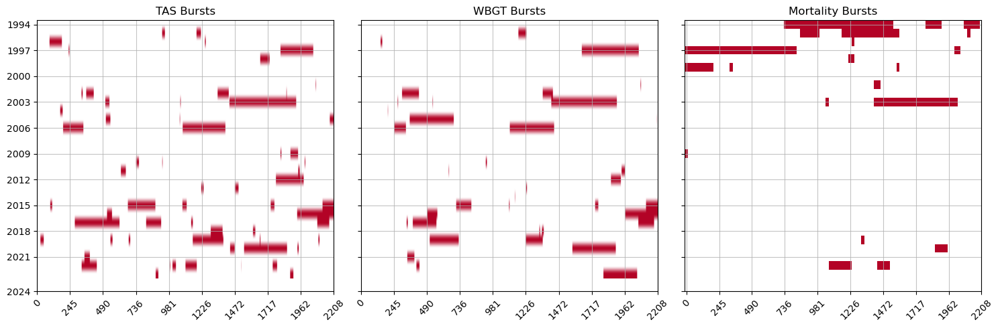

In [17]:
cmap = plt.cm.coolwarm  
cmap.set_bad('white') 
cmap.set_under('white')  

vmin = min(np.nanmin(grid_tas_bursts), np.nanmin(grid_wbgt_bursts), np.nanmin(grid_mort_bursts))
vmax = max(np.nanmax(grid_tas_bursts), np.nanmax(grid_wbgt_bursts), np.nanmax(grid_mort_bursts))

xticks = np.linspace(0, 92 * 24, num=10, dtype=int)
yticks = np.linspace(0, n_year-20+1, num=11, dtype=int)
yticks_labels = np.linspace(1994, 2023+1, num=11, dtype=int)

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

im1 = axes[0].imshow(np.ma.masked_equal(grid_tas_bursts, 0), cmap=cmap, vmin=vmin, vmax=vmax, aspect='auto')
axes[0].set_title("TAS Bursts")
axes[0].grid(alpha=0.75)

im2 = axes[1].imshow(np.ma.masked_equal(grid_wbgt_bursts, 0), cmap=cmap, vmin=vmin, vmax=vmax, aspect='auto')
axes[1].set_title("WBGT Bursts")
axes[1].grid(alpha=0.75)

im3 = axes[2].imshow(np.ma.masked_equal(grid_mort_bursts, 0), cmap=cmap, vmin=vmin, vmax=vmax, aspect='auto')
axes[2].set_title("Mortality Bursts")
axes[2].grid(alpha=0.75)


axes[0].set_xticks(xticks)
axes[0].set_xticklabels(xticks, rotation=45)
axes[1].set_xticks(xticks)
axes[1].set_xticklabels(xticks, rotation=45)
axes[2].set_xticks(xticks/24)
axes[2].set_xticklabels(xticks, rotation=45)

axes[0].set_yticks(yticks)
axes[0].set_yticklabels(yticks_labels)
axes[1].set_yticks(yticks)
axes[1].set_yticklabels(yticks_labels)
axes[2].set_yticks(yticks)
axes[2].set_yticklabels(yticks_labels)



plt.tight_layout()
plt.show()

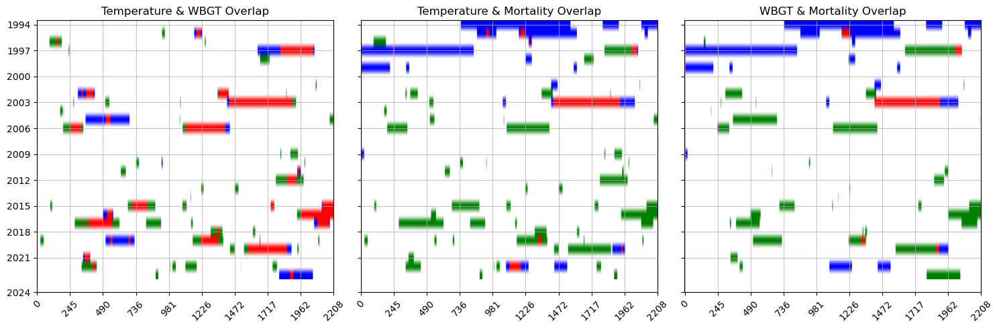

In [18]:
grid_mort_bursts_expanded = np.repeat(grid_mort_bursts, 24, axis=1) 

def create_color_grid(grid1, grid2):
    color_grid = np.zeros_like(grid1)  # 
    color_grid[(grid1 == 1) & (grid2 == 0)] = 1 
    color_grid[(grid1 == 0) & (grid2 == 1)] = 2 
    color_grid[(grid1 == 1) & (grid2 == 1)] = 3 
    return color_grid

color_tas_mort = create_color_grid(grid_tas_bursts, grid_mort_bursts_expanded)
color_tas_wbgt = create_color_grid(grid_tas_bursts, grid_wbgt_bursts)
color_wbgt_mort = create_color_grid(grid_wbgt_bursts, grid_mort_bursts_expanded)

cmap = mcolors.ListedColormap(["white", "green", "blue", "red"])
bounds = [0, 1, 2, 3, 4]  
norm = mcolors.BoundaryNorm(bounds, cmap.N)
xticks = np.linspace(0, 92 * 24, num=10, dtype=int)
yticks = np.linspace(0, n_year - 20 + 1, num=11, dtype=int)
yticks_labels = np.linspace(1994, 2023 + 1, num=11, dtype=int)

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
im1 = axes[1].imshow(color_tas_mort, cmap=cmap, norm=norm, aspect='auto')
axes[1].set_title("Temperature & Mortality Overlap")
axes[1].grid(alpha=0.75)

im2 = axes[0].imshow(color_tas_wbgt, cmap=cmap, norm=norm, aspect='auto')
axes[0].set_title("Temperature & WBGT Overlap")
axes[0].grid(alpha=0.75)

im3 = axes[2].imshow(color_wbgt_mort, cmap=cmap, norm=norm, aspect='auto')
axes[2].set_title("WBGT & Mortality Overlap")
axes[2].grid(alpha=0.75)

for ax in axes:
    ax.set_xticks(xticks)
    ax.set_xticklabels(xticks, rotation=45)
    ax.set_yticks(yticks)
    ax.set_yticklabels(yticks_labels)

plt.tight_layout()
plt.show()
